# Detección facial con dlib: Landmarks y Medición de pose

`Colab para procesamiento de imágenes, reconocimiento de patrones y visión por computador`

Basado en los materiales de [Domingo Mery](https://domingomery.ing.puc.cl/) — Pontificia Universidad Católica de Chile.

---

Este cuaderno cubre dos tareas con **dlib**:

1. **Face Landmarks** — los 68 puntos característicos del rostro.
2. **Medición de pose de la cara** — dirección estimada de la cara.

> El *Face Mesh* no se incluye aquí porque depende de MediaPipe. dlib resuelve landmarks y pose sin esa dependencia.

## Instalación e imports

In [ ]:
# dlib puede tardar un poco la primera vez.
!pip install -q dlib

In [ ]:
import dlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Modelo de puntos (shape predictor)

Descargamos el archivo `.dat` de 68 puntos desde GitHub.

In [ ]:
!wget -q -O shape_predictor_68_face_landmarks.dat \
  https://raw.githubusercontent.com/Practical-CV/Facial-Landmarks-Detection-with-DLIB/master/shape_predictor_68_face_landmarks.dat

# Verificación rápida: debe pesar ~99 MB. Si sale muy chico, la descarga falló.
import os
print('Tamaño (MB):', round(os.path.getsize('shape_predictor_68_face_landmarks.dat')/1e6, 1))

detector  = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor('shape_predictor_68_face_landmarks.dat')

Tamaño (MB): 99.7


## Creamos funciones

In [ ]:
def detectar_landmarks(img):
  bb    = detector(img, 1)[0]   # primera cara detectada
  shape = predictor(img, bb)

  # bounding box recortado a los límites de la imagen
  y1 = max(0, bb.top())
  y2 = min(bb.bottom(), img.shape[0])
  x1 = max(0, bb.left())
  x2 = min(bb.right(), img.shape[1])

  # 68 puntos a arrays de píxeles
  x = np.zeros((68,))
  y = np.zeros((68,))
  for i in range(68):
      x[i] = shape.part(i).x
      y[i] = shape.part(i).y
  return [x, y, x1, y1, x2, y2]

def mostrar_landmarks(img, puntos):
  x, y, x1, y1, x2, y2 = puntos
  plt.figure(figsize=(10, 12))
  plt.imshow(img)
  plt.title('Face Landmarks (68 puntos)')
  plt.scatter(x, y, s=15, c='lime')
  for i in range(68):
      plt.text(x[i], y[i], str(i), c='white', fontsize=7)
  plt.plot([x1, x1, x2, x2, x1], [y1, y2, y2, y1, y1], c='yellow')
  plt.axis('off')
  plt.show()

def estimar_pose(x, y):
    """
    Estima la pose de la cara a partir de los 68 landmarks.
    Recibe: x, y (arrays de 68 puntos).
    Devuelve un dict con todo lo necesario para dibujar y/o medir.
    """
    x_eye_left    = x[36]; y_eye_left    = y[36]
    x_eye_right   = x[45]; y_eye_right   = y[45]
    x_mouth_left  = x[48]; y_mouth_left  = y[48]
    x_mouth_right = x[54]; y_mouth_right = y[54]

    xp = [x_eye_left, x_eye_right, x_mouth_right, x_mouth_left, x_eye_left]
    yp = [y_eye_left, y_eye_right, y_mouth_right, y_mouth_left, y_eye_left]

    m1 = [xp[0], yp[0], 1]
    m2 = [xp[1], yp[1], 1]
    m3 = [xp[3], yp[3], 1]
    m4 = [xp[2], yp[2], 1]

    ell_1 = np.cross(m1, m4)
    ell_2 = np.cross(m2, m3)
    mc    = np.cross(ell_1, ell_2)
    xc    = mc[0] / mc[2]
    yc    = mc[1] / mc[2]

    mn = [x[33], y[33], 1]   # nariz
    xn = mn[0]
    ell_n = np.cross(mc, mn)
    a, b, c = ell_n

    dr = xn - xc
    xr = xc + 4 * dr
    yr = -(a * xr + c) / b

    xt = (m1[0] + m2[0]) / 2
    yt = (m1[1] + m2[1]) / 2
    dx = xr - xc
    dy = yr - yc
    d  = np.sqrt(dx*dx + dy*dy)

    return {
        'xp': xp, 'yp': yp,       # cuadrilátero (ojos + boca)
        'centro': (xc, yc),       # cruce de diagonales
        'origen': (xt, yt),       # base de la flecha (entre los ojos)
        'vector': (dx, dy),       # dirección de la flecha
        'largo': d,               # largo de la flecha
    }


def mostrar_pose(img, pose, bbox=None):
    """
    Dibuja la pose estimada sobre la imagen.
    Recibe: img (RGB), pose (dict de estimar_pose) y, opcionalmente,
    bbox = (x1, y1, x2, y2) para dibujar la caja del rostro.
    """
    xc, yc = pose['centro']
    xt, yt = pose['origen']
    dx, dy = pose['vector']
    d      = pose['largo']

    plt.figure(figsize=(10, 12))
    plt.imshow(img)
    plt.scatter(pose['xp'], pose['yp'], s=20, c='red')
    plt.plot(pose['xp'], pose['yp'], c='yellow')
    plt.arrow(xt, yt, dx, dy, color='red', head_width=d/10, head_length=d/5)
    if bbox is not None:
        x1, y1, x2, y2 = bbox
        plt.plot([x1, x1, x2, x2, x1], [y1, y2, y2, y1, y1])
    plt.title('Pose de la cara (dirección estimada)')
    plt.axis('off')
    plt.show()

## Imagen de prueba

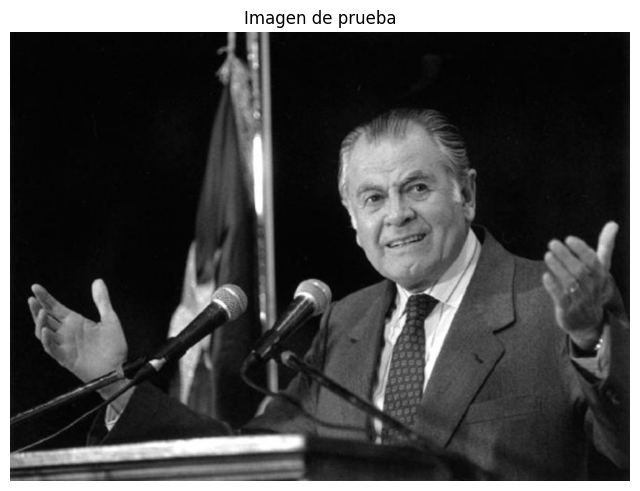

In [ ]:
!wget -q -O Aylwin-1.jpg \
  "https://www.dropbox.com/scl/fi/86wluoxejyhdf6se34u1v/Aylwin-1.jpg?rlkey=84bkjubpwyqxe7cv3oo5fsoue&dl=1"

nombre_img = 'Aylwin-1.jpg'
img = dlib.load_rgb_image(nombre_img)   # dlib carga directamente en RGB

plt.figure(figsize=(8, 10))
plt.imshow(img)
plt.title('Imagen de prueba')
plt.axis('off')
plt.show()

## Detección de rostro y landmarks

Detectamos la cara, obtenemos los 68 puntos y los dibujamos numerados.

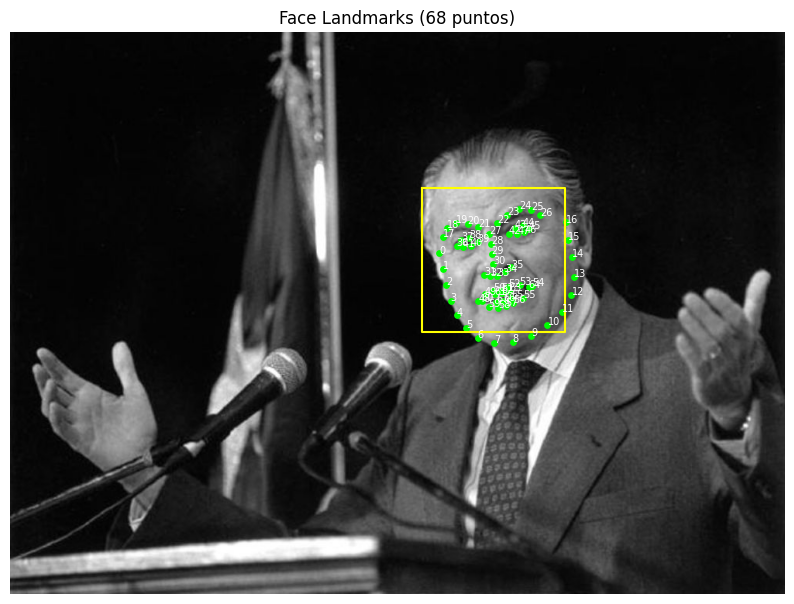

In [ ]:
puntos = detectar_landmarks(img)
mostrar_landmarks(img, puntos)

## Medición de pose de la cara

Con dos ojos y dos comisuras de la boca se forma un cuadrilátero; el cruce de sus diagonales da un centro. La recta de ese centro a la **nariz** marca la dirección, que prolongamos como flecha.

Índices dlib: ojos `36`/`45`, boca `48`/`54`, nariz `33`.

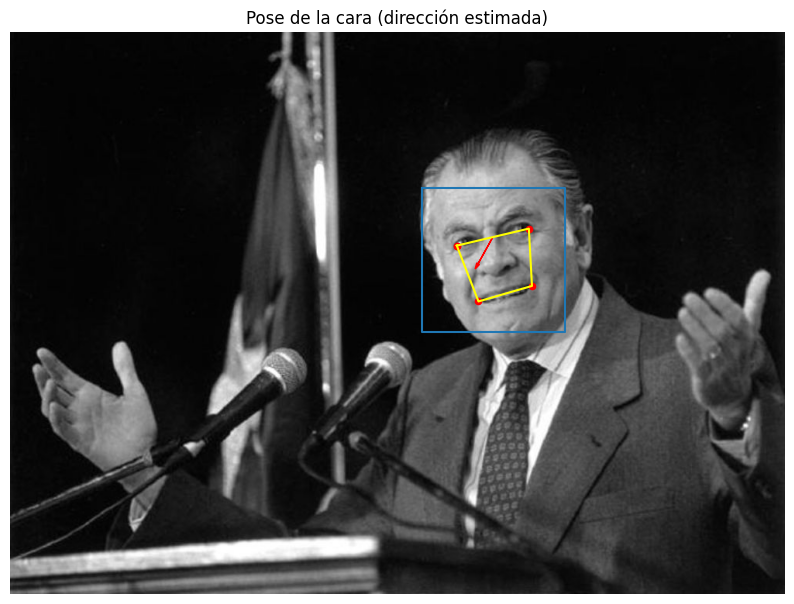

In [ ]:
x, y, x1, y1, x2, y2 = puntos
bbox = [x1, y1, x2, y2]
pose = estimar_pose(x, y)
mostrar_pose(img, pose, bbox)

In [ ]:
!wget -q -O Aylwin-2.jpg \
  "https://www.dropbox.com/scl/fi/s09zbss4crkhbh57psoa6/Aylwin-2.jpg?rlkey=r6sowfxjmcr1xqtx0veo16yoc&st=juuorzyg&dl=0"
!wget -q -O Aylwin-3.tiff \
  "https://www.dropbox.com/scl/fi/gpsmz5lue2r1ls92d4m9v/Aylwin-3.jfif?rlkey=05xxingm33vymai50pknywsf2&st=slbfyx3o&dl=0"

nombre_img_2 = 'Aylwin-2.jpg'
img = dlib.load_rgb_image(nombre_img_2)   # dlib carga directamente en RGB

nombre_img_3 = 'Aylwin-3.tiff'
img = dlib.load_rgb_image(nombre_img_3)   # dlib carga directamente en RGB

# mostramos lado a lado


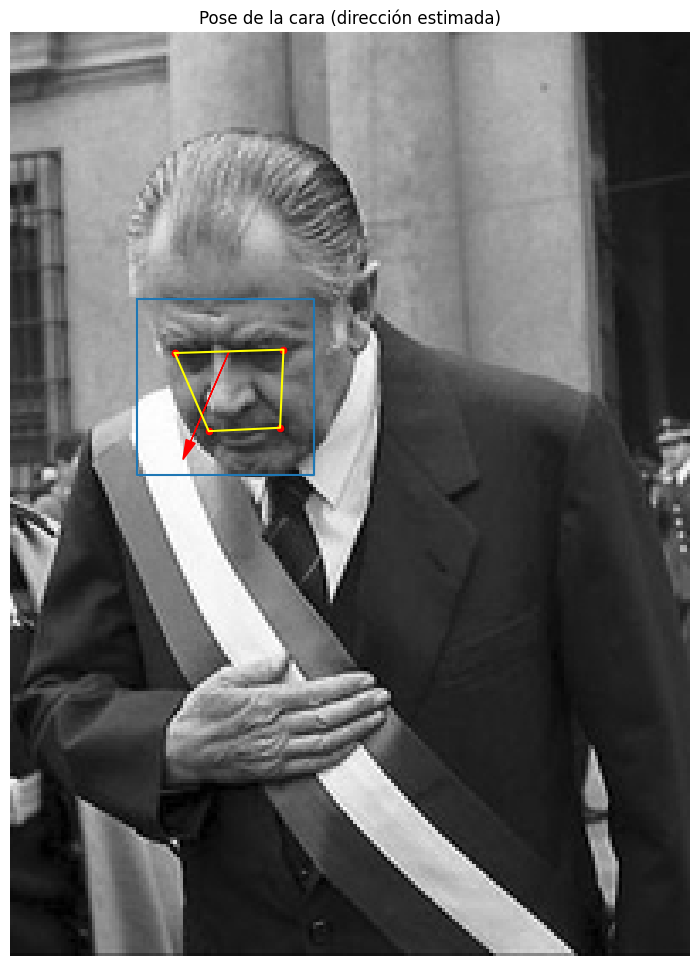

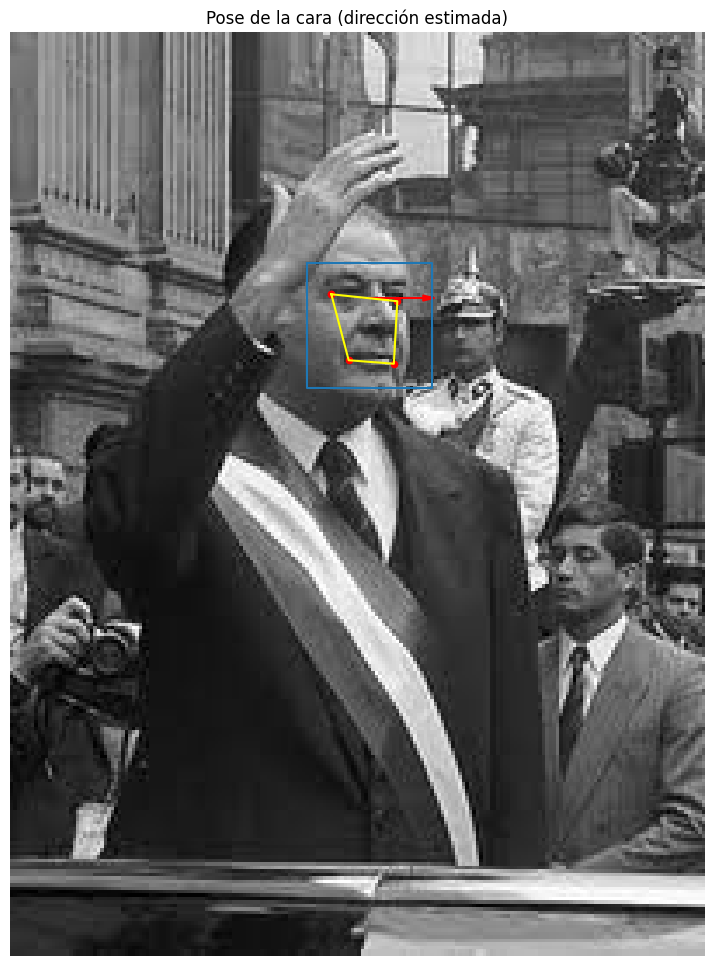

In [ ]:
def estimar_pose_completo(nombre_img):
  img = dlib.load_rgb_image(nombre_img)
  puntos = detectar_landmarks(img)
  x, y, x1, y1, x2, y2 = puntos
  bbox = [x1, y1, x2, y2]
  pose = estimar_pose(x, y)
  mostrar_pose(img, pose, bbox)

estimar_pose_completo('Aylwin-2.jpg')
estimar_pose_completo('Aylwin-3.tiff')

# Mallado de cara
Hacemos el mallado de cara mediante mediapipe

basado en:

https://colab.research.google.com/github/googlesamples/mediapipe/blob/main/examples/face_landmarker/python/%5BMediaPipe_Python_Tasks%5D_Face_Landmarker.ipynb#scrollTo=xixKF10-rms

In [ ]:
!pip install mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 40.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 8.7 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


## Cargamos librerías

In [ ]:
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision



# Imagen de prueba

In [ ]:
!wget -q -O cara-1.jpeg \
https://www.dropbox.com/scl/fi/228z8mlr5zykvmm89qin4/cara_1.jpeg?rlkey=2imdgb7pbqkm3mbgqdy3plipf&st=gsv2ecik&dl=0


Descargamos el modelo .task para encontrar los landmarks del facemesh

In [ ]:
!wget https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task
model_path = 'face_landmarker.task'

--2026-06-26 18:27:32--  https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/latest/face_landmarker.task
Resolving storage.googleapis.com (storage.googleapis.com)... 64.233.189.207, 108.177.97.207, 108.177.125.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|64.233.189.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3758596 (3.6M) [application/octet-stream]
Saving to: ‘face_landmarker.task’

face_landmarker.tas 100%[===================>]   3.58M  3.01MB/s    in 1.2s    

2026-06-26 18:27:35 (3.01 MB/s) - ‘face_landmarker.task’ saved [3758596/3758596]



In [ ]:
#@markdown We implemented some functions to visualize the face landmark detection results. <br/> Run the following cell to activate the functions.
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from mediapipe.tasks.python.vision import drawing_utils
from mediapipe.tasks.python.vision import drawing_styles
import numpy as np
import matplotlib.pyplot as plt


def draw_landmarks_on_image(rgb_image, detection_result):
  face_landmarks_list = detection_result.face_landmarks
  annotated_image = np.copy(rgb_image)

  # Loop through the detected faces to visualize.
  for idx in range(len(face_landmarks_list)):
    face_landmarks = face_landmarks_list[idx]

    # Draw the face landmarks.


    drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks,
        connections=vision.FaceLandmarksConnections.FACE_LANDMARKS_TESSELATION,
        landmark_drawing_spec=None,
        connection_drawing_spec=drawing_styles.get_default_face_mesh_tesselation_style())
    drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks,
        connections=vision.FaceLandmarksConnections.FACE_LANDMARKS_CONTOURS,
        landmark_drawing_spec=None,
        connection_drawing_spec=drawing_styles.get_default_face_mesh_contours_style())
    drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks,
        connections=vision.FaceLandmarksConnections.FACE_LANDMARKS_LEFT_IRIS,
          landmark_drawing_spec=None,
          connection_drawing_spec=drawing_styles.get_default_face_mesh_iris_connections_style())
    drawing_utils.draw_landmarks(
        image=annotated_image,
        landmark_list=face_landmarks,
        connections=vision.FaceLandmarksConnections.FACE_LANDMARKS_RIGHT_IRIS,
          landmark_drawing_spec=None,
          connection_drawing_spec=drawing_styles.get_default_face_mesh_iris_connections_style())

  return annotated_image

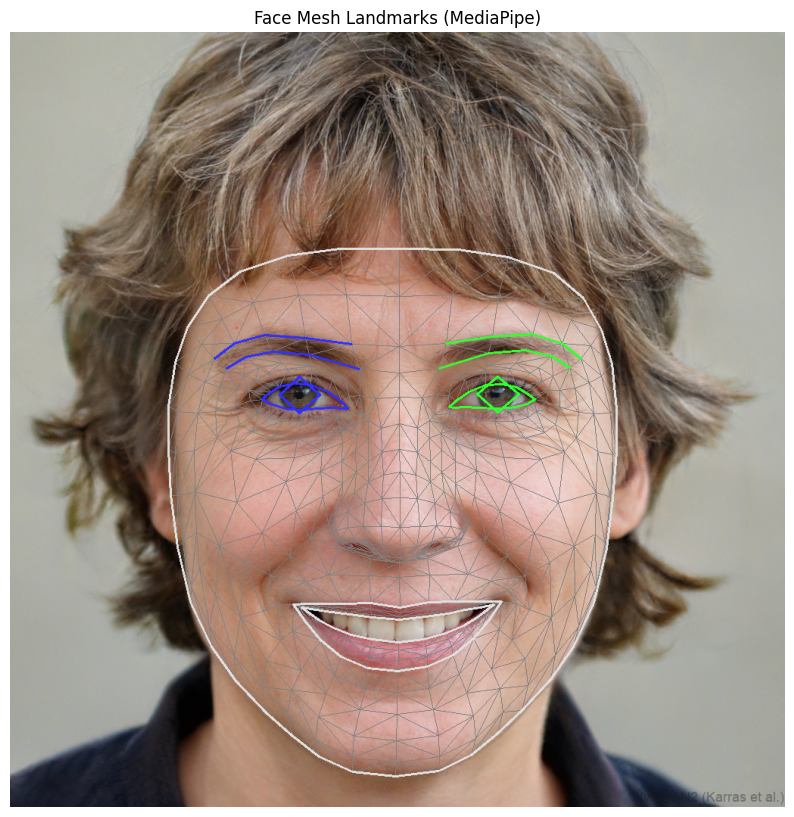

In [ ]:
base_options = python.BaseOptions(model_asset_path='face_landmarker.task')
options = vision.FaceLandmarkerOptions(base_options=base_options,
                                       output_face_blendshapes=True,
                                       output_facial_transformation_matrixes=True,
                                       num_faces=1)
detector = vision.FaceLandmarker.create_from_options(options)

image = mp.Image.create_from_file("cara-1.jpeg")

detection_result = detector.detect(image)

annotated_image = draw_landmarks_on_image(image.numpy_view(), detection_result)
plt.figure(figsize=(10, 12))
plt.imshow(annotated_image)
plt.title('Face Mesh Landmarks (MediaPipe)')
plt.axis('off')
plt.show()

---
*Cuaderno adaptado para el módulo de Visión por Computador del diplomado de inteligencia artificial aplicada a la industria tecnológica · Universidad de Santiago de Chile.*
---
<a href="https://example.com">01_Landmarks_facemesh.ipynb</a> © 2026 by <a href="https://example.com">Diego Fischer</a> is licensed under <a href="https://creativecommons.org/licenses/by/4.0/">CC BY 4.0</a><img src="https://mirrors.creativecommons.org/presskit/icons/cc.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;"><img src="https://mirrors.creativecommons.org/presskit/icons/by.svg" alt="" style="max-width: 1em;max-height:1em;margin-left: .2em;">